In [1]:
import sys
sys.path.append("..")  # Permet d'importer depuis le dossier src/

import torch
import pandas as pd
import matplotlib.pyplot as plt

from src.data import get_train_test_datasets
from src.pricing import (
    bs_call_price,
    bs_delta_strategy,
    naive_strategy,
    compute_hedging_pnl,
    summarize_pnl,
)

# Paramètres standards du marché simulé
S0 = 100.0
K = 100.0
T = 1.0
r = 0.03
sigma = 0.20
n_steps = 30      # Rebalancement quotidien sur 30 pas (tester aussi 252)
c = 1e-3          # Coût de transaction proportionnel (0.1 %)

prime_bs = bs_call_price(S0, K, T, r, sigma)
print(f"Prix théorique Black-Scholes du Call : {prime_bs:.4f}")

Prix théorique Black-Scholes du Call : 9.4134


Train : torch.Size([100000, 31]) | Test : torch.Size([20000, 31])


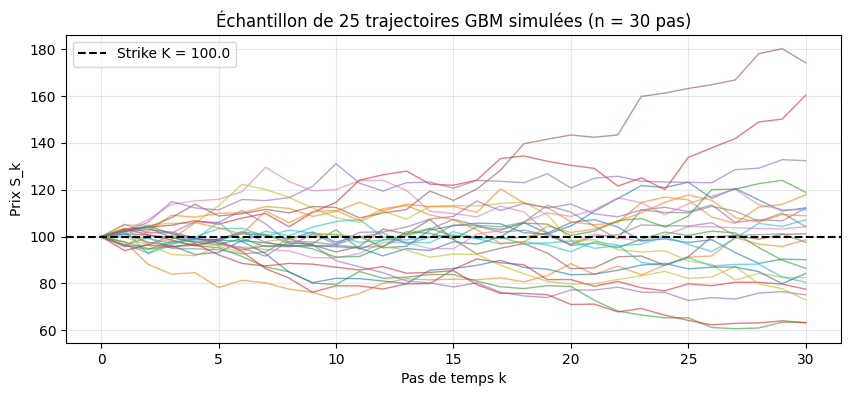

In [2]:
train_S, test_S = get_train_test_datasets(
    S0=S0, r=r, sigma=sigma, T=T, n_steps=n_steps,
    train_paths=100_000, test_paths=20_000
)

print("Train :", train_S.shape, "| Test :", test_S.shape)

plt.figure(figsize=(10, 4))
for i in range(25):
    plt.plot(test_S[i].numpy(), alpha=0.6, linewidth=1)
plt.axhline(K, color="black", linestyle="--", label=f"Strike K = {K}")
plt.title(f"Échantillon de 25 trajectoires GBM simulées (n = {n_steps} pas)")
plt.xlabel("Pas de temps k")
plt.ylabel("Prix S_k")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [3]:
# 1. Stratégie naïve : aucune couverture (delta = 0)
deltas_no_hedge = naive_strategy(test_S, mode="no_hedge")
pnl_no_hedge, cost_no_hedge = compute_hedging_pnl(
    test_S, deltas_no_hedge, K, c=c, include_premium=True, premium=prime_bs
)

# 2. Couverture Delta Black-Scholes SANS coûts de transaction (c = 0)
deltas_bs = bs_delta_strategy(test_S, K, T, r, sigma)
pnl_bs_no_cost, cost_bs_zero = compute_hedging_pnl(
    test_S, deltas_bs, K, c=0.0, include_premium=True, premium=prime_bs
)

# 3. Couverture Delta Black-Scholes AVEC coûts de transaction (c = 0.001)
pnl_bs_cost, cost_bs = compute_hedging_pnl(
    test_S, deltas_bs, K, c=c, include_premium=True, premium=prime_bs
)

# Tableau récapitulatif des indicateurs
results = pd.DataFrame({
    "Sans couverture (Naïve)": summarize_pnl(pnl_no_hedge, cost_no_hedge),
    "Delta BS (c = 0)": summarize_pnl(pnl_bs_no_cost, cost_bs_zero),
    f"Delta BS (c = {c})": summarize_pnl(pnl_bs_cost, cost_bs),
}).T

display(results.round(4))

,Moyenne P&L,Écart-type P&L,Quantile 5% (VaR 95%),Coût transaction moyen
Sans couverture (Naïve),-0.2030,14.4657,-30.7962,0.0000
Delta BS (c = 0),1.5274,1.4082,-0.8227,0.0000
Delta BS (c = 0.001),1.2992,1.4201,-1.0846,0.2282


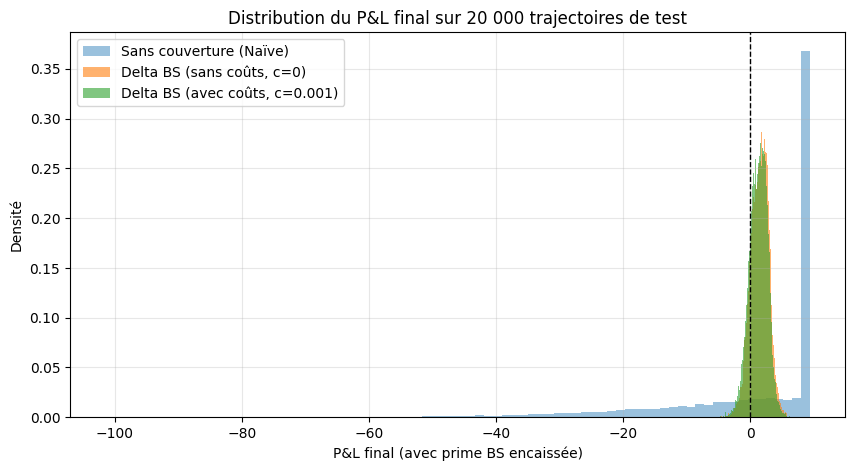

In [4]:
plt.figure(figsize=(10, 5))
plt.hist(pnl_no_hedge.numpy(), bins=80, alpha=0.45, density=True, label="Sans couverture (Naïve)")
plt.hist(pnl_bs_no_cost.numpy(), bins=80, alpha=0.6, density=True, label="Delta BS (sans coûts, c=0)")
plt.hist(pnl_bs_cost.numpy(), bins=80, alpha=0.6, density=True, label=f"Delta BS (avec coûts, c={c})")
plt.axvline(0, color="black", linestyle="--", linewidth=1)
plt.title("Distribution du P&L final sur 20 000 trajectoires de test")
plt.xlabel("P&L final (avec prime BS encaissée)")
plt.ylabel("Densité")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

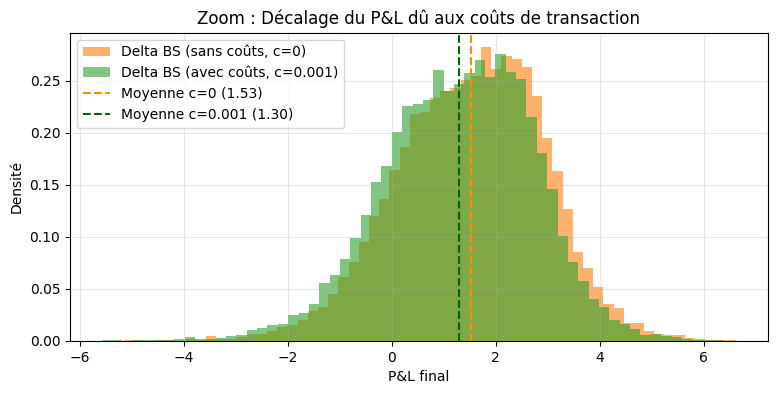

In [5]:
# Cellule 5 : Zoom sur l'effet des coûts de transaction (Delta BS c=0 vs c=0.001)
plt.figure(figsize=(9, 4))
plt.hist(pnl_bs_no_cost.numpy(), bins=60, alpha=0.6, density=True, color="tab:orange", label="Delta BS (sans coûts, c=0)")
plt.hist(pnl_bs_cost.numpy(), bins=60, alpha=0.6, density=True, color="tab:green", label=f"Delta BS (avec coûts, c={c})")
plt.axvline(pnl_bs_no_cost.mean().item(), color="darkorange", linestyle="--", label=f"Moyenne c=0 ({pnl_bs_no_cost.mean():.2f})")
plt.axvline(pnl_bs_cost.mean().item(), color="darkgreen", linestyle="--", label=f"Moyenne c={c} ({pnl_bs_cost.mean():.2f})")
plt.title("Zoom : Décalage du P&L dû aux coûts de transaction")
plt.xlabel("P&L final")
plt.ylabel("Densité")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()